# **ECON6113 Final Project: What Makes a Hit Song?**
**Researchers: Alex Griffa, Preet Khimasia, Shakthi Kannan, Yusuf Mirasyedi**

##**1. Research Question and Importance**  

In an alternate world, we are researchers hired by Aspy Records to find what makes a song popular.

**Are higher-valence tracks associated with more streams after accounting for other audio features and genre?**


The record executives at Aspy believe that 'valence', a measure of "how happy a song sounds", is key to making the next hit song. To test their theory, we, the researchers, have determnined that 'streams' is the most suitable variabe to test against. We use 'streams' as our dependent variable because it is a measurable proxy of a song's popularity.

As a fledgling label in the music industry, Aspy Records does not have the most sophisticated dataset, but were kind enough to provide a sample of 10,000 individual music tracks containing information across 17 different variables. Below is an analysis of our findings broken down in seven parts:

1. Valence ~ Streams: A Naive Estimation
2. Valence and Friends ~ Streams: A More Sophisticated Regression
3. Valence and More Friends ~ Streams: A Thorough Analysis
4. Limitations and Further Questions
5. Preferred Regression and Diagnostics
6. Limitations & Avenues for Further Research
7. Conclusions

However, we must first introduce our dataset, aptly titled: *What Makes a Song go Viral?*

Data source: https://www.kaggle.com/datasets/vedauv/what-makes-a-song-go-viral-10000-tracks/data


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
import seaborn as sns
from scipy import stats
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os

###1.1 Prelude: *What Makes a Song Go Viral?*

This dataset contains 17 Columns. Below we list the columns and their definitions, according to the data source.


1.  ```track_id```:	Unique identifier
2.  ```track_name```:	Name of the track (Kept anonymous)
3.  ```artist_name```:	Name of the artist (Kept anonymous)
4.  ```genre```:	Musical genre (10 categories: Pop, Rock, Hip-Hop, Latin, Indie, Electronic, Classical, Jazz, R&B, Country)
5.  ```release_year```:	Year of track release (2010 – 2025)
6.  ```duration_sec```:	Total track length in seconds
7.  ```danceability```:	Suitability for dancing (0.0 to 1.0)
8.  ```energy```:	Perceptual measure of sonic intensity and activity (0.0 to 1.0)
9.  ```valence```:	**Musical positiveness and mood conveyed (0.0 to 1.0)**
10. ```tempo_bpm```:	Estimated track tempo in beats per minute
11. ```acousticness```:	Confidence measure of acoustic instrumentation (0.0 to 1.0)
12. ```instrumentalness```:	Likelihood that the track contains no vocal content (0.0 to 1.0)
13. ```speechiness```:	Presence of spoken words vs. musical singing (0.0 to 1.0)
14. ```liveness```:	Probability of audience presence / live recording (0.0 to 1.0)
15. ```loudness_db```:	Overall track loudness in decibels (dB)
16. ```streams```:	Historical playback stream volume
17. ```viral```:	Target variable (1 = viral track, 0 = non-viral track)


In [ ]:
# Set the path to the file you'd like to load (the main CSV file in the dataset)
file_path = "viral_songs.csv"

# Load the latest version using the recommended dataset_load
df_songs = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "vedauv/what-makes-a-song-go-viral-10000-tracks",
  file_path
)

display(df_songs.head())

Using Colab cache for faster access to the 'what-makes-a-song-go-viral-10000-tracks' dataset.


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


In [ ]:
# Summarize the outcome and audio variables used in the regressions.
model_columns = ["streams", "valence", "tempo_bpm", "acousticness", "duration_sec"]
model_data = df_songs[model_columns]

summary_stats = model_data.describe().T.rename(columns={
    "count": "Observed", "mean": "Mean", "std": "SD",
    "25%": "25th percentile", "50%": "Median", "75%": "75th percentile",
})
summary_stats["Observed"] = summary_stats["Observed"].astype(int)
summary_stats["Missing"] = model_data.isna().sum()
summary_stats = summary_stats[[
    "Observed", "Missing", "Mean", "SD", "25th percentile", "Median", "75th percentile",
]]
summary_stats.index.name = "Variable"

print(f"Descriptive statistics for {len(df_songs):,} tracks")
display(summary_stats.style.format(precision=3, thousands=","))

# Count every track in the genre distribution, including missing labels.
genre_counts = df_songs["genre"].fillna("Missing").value_counts()
genre_summary = genre_counts.to_frame("Tracks")
genre_summary["Share of sample (%)"] = 100 * genre_counts / len(df_songs)
genre_summary.index.name = "Genre"
print("Tracks by genre")
display(genre_summary.style.format({"Tracks": "{:,}", "Share of sample (%)": "{:.1f}"}))

Descriptive statistics for 10,000 tracks


,Observed,Missing,Mean,SD,25th percentile,Median,75th percentile
Variable,,,,,,,
streams,"10,000",0,"2,415,684.823","9,721,026.138","86,714.500","329,058.000","1,343,091.750"
valence,"10,000",0,0.582,0.178,0.459,0.582,0.703
tempo_bpm,"10,000",0,110.976,19.017,98.000,111.300,124.500
acousticness,"10,000",0,0.296,0.264,0.085,0.235,0.441
duration_sec,"10,000",0,208.777,49.967,175.000,209.000,242.000


Tracks by genre


,Tracks,Share of sample (%)
Genre,,
Rock,"1,084",10.8
Hip-Hop,"1,052",10.5
Latin,"1,030",10.3
Pop,"1,002",10.0
Indie,993,9.9
Electronic,991,9.9
Classical,991,9.9
Jazz,965,9.7
R&B,950,9.5


##2. Valence ~ Streams: A Naive Estimation

As requested by the executives at Aspy Records, we, the researchers, present to you a simple estimation to the explore the effects of ```valence``` on ```streams```. According to the classic linear model we are estimating:

$$y = \beta_0 + \beta_1 x + u  ⇒ \text{streams} = \beta_0 + \beta_1 \text{valence} + u$$

Using Ordinary Least Squares (OLS), and assuming relevant simple linear regression (SLR) assumptions hold, we obtain the following:

$$\widehat{\text{streams}} = \hat{\beta_0} + \hat{\beta_1}\text {valence}$$

Before we continue, we must provide an explanation of how ```valence``` is calculated. In short, ```valence``` is calculated through an internal, proprietary model developed by Spotify. From our research on the subject, the calculation takes musical characteristics, including the chords and lyrics into account, but the complete methodology remains undisclosed.

,Variable,Coefficient,Std Error,t-statistic,P-value
0,Intercept,7.388728e+05,332121.7597,2.2247,0.0261
1,valence,2.879733e+06,545470.4222,5.2794,0.0000


,Statistic,Value
0,R-squared,0.0028
1,Adjusted R-squared,0.0027
2,F-statistic,27.87
3,Observations,10000


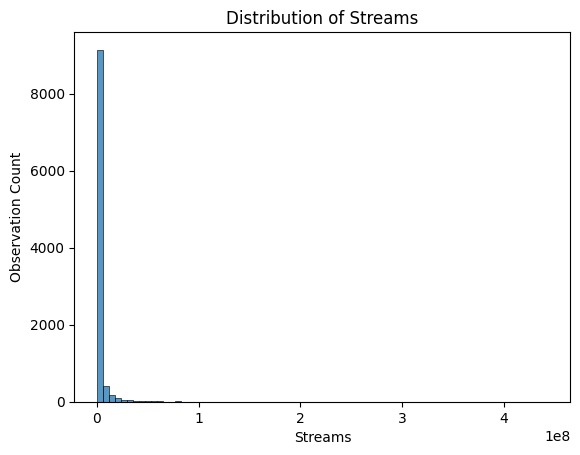

In [ ]:

# Start with an unadjusted OLS benchmark. The slope is measured in streams per
# 1.0 increase in valence, so multiply it by 0.01 for a 0.01 increase.

reg = smf.ols('streams ~ valence', data = df_songs).fit()

# Print regression table
coef_table = pd.DataFrame(
    {
        "Variable": reg.params.index,
        "Coefficient": reg.params.values,
        "Std Error": reg.bse.values,
        "t-statistic": reg.tvalues.values,
        "P-value": reg.pvalues.values,
    }
)

# Model Statistics
model_stats = pd.DataFrame(
    {
        "Statistic": [
            "R-squared",
            "Adjusted R-squared",
            "F-statistic",
            "Observations",
        ],
        "Value": [
            f"{reg.rsquared:.4f}",
            f"{reg.rsquared_adj:.4f}",
            f"{reg.fvalue:.2f}",
            f"{int(reg.nobs)}",
        ],
    }
)

display(coef_table.round(4))
display(model_stats)
sns.histplot(df_songs, x='streams', bins=75)
plt.xlabel('Streams')
plt.ylabel('Observation Count')
plt.title('Distribution of Streams')
plt.show()


###2.1 Bias And Improved Naive Estimation

The naive regression estimates $Y_i = \alpha_0 + \alpha_1 V_i + u_i$, where $Y_i$ is the stream count and $V_i$ is valence. For the 10,000 tracks, the fitted equation is

$$
\widehat{\mathrm{streams}}_i = 738{,}872.83 + 2{,}879{,}733.34\,\mathrm{valence}_i.
$$

**Why the naive slope can be too high.** Let $A_i$ denote acousticness. Compare the naive model with $Y_i = \beta_0 + \beta_1 V_i + \beta_2 A_i + \varepsilon_i$. On the same sample, the omitted-variable formula gives

$$
\widehat{\alpha}_1 - \widehat{\beta}_1 = \widehat{\beta}_2\,\widehat{\delta}_1,
$$

where $\widehat{\delta}_1$ is the slope from regressing acousticness on valence. In this sample, higher valence is associated with lower acousticness ($\widehat{\delta}_1=-0.25493$), and higher acousticness is associated with fewer streams at the same valence ($\widehat{\beta}_2=-3{,}290{,}668.97$). The product is positive.

$$
2{,}879{,}733.34 - 2{,}040{,}845.34
\approx (-3{,}290{,}668.97)(-0.25493)
\approx 838{,}888.
$$

Omitting acousticness raises the fitted valence slope by about **838,888 streams per one-unit increase in valence**, relative to the model that controls for acousticness. This comparison describes the change between two observational regressions. Interpreting it as causal bias would require the adjusted model to identify a causal effect.

Raw streams are heavily right-skewed. We next fit the simple regression on natural log streams so that we can describe the relationship in percentage terms.

$$
\widehat{\log(\mathrm{streams})}_i = \widehat{\gamma}_0 + \widehat{\gamma}_1\,\mathrm{valence}_i.
$$

,Variable,Coefficient,Std Error,t-statistic,P-value
0,Intercept,11.9580,0.0683,175.1105,0.0
1,valence,1.3676,0.1122,12.1940,0.0


,Statistic,Value
0,R-squared,0.0147
1,Adjusted R-squared,0.0146
2,F-statistic,148.69
3,Observations,10000


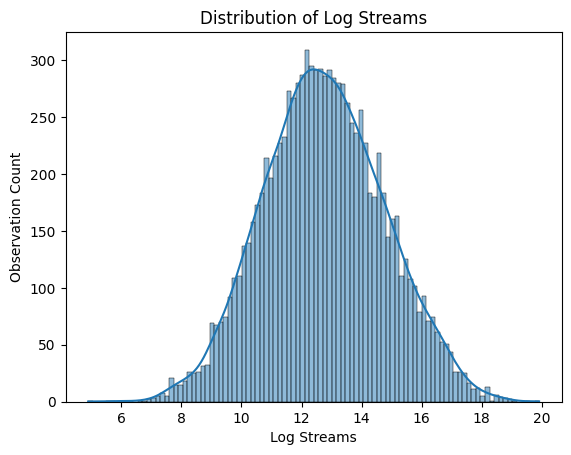

Simple regression comparison (10,000 tracks)


,Naive OLS (streams),Simple log OLS (log streams)
Term,,
Intercept,"738,873",11.9580
Valence coefficient,"2,879,733",1.3676
Change for +0.10 valence,"+287,973 streams",+14.66% in fitted geometric mean streams


In [ ]:
# Take the natural log to compress the right tail of the stream counts.
# For a 0.01 increase in valence, exp(0.01 * slope) - 1 gives the proportional
# change in fitted geometric mean streams.
#logging streams to make it linear and still naive, bias is still present
reg = smf.ols('np.log(streams) ~ valence', data = df_songs).fit()

# Display regression results in a clean table
coef_table = pd.DataFrame(
    {
        "Variable": reg.params.index,
        "Coefficient": reg.params.values,
        "Std Error": reg.bse.values,
        "t-statistic": reg.tvalues.values,
        "P-value": reg.pvalues.values,
    }
)

# Model Statistics
model_stats = pd.DataFrame(
    {
        "Statistic": [
            "R-squared",
            "Adjusted R-squared",
            "F-statistic",
            "Observations",
        ],
        "Value": [
            f"{reg.rsquared:.4f}",
            f"{reg.rsquared_adj:.4f}",
            f"{reg.fvalue:.2f}",
            f"{int(reg.nobs)}",
        ],
    }
)

display(coef_table.round(4))
display(model_stats)

sns.histplot(np.log(df_songs['streams']), bins=100, kde=True)
plt.xlabel('Log Streams')
plt.ylabel('Observation Count')
plt.title('Distribution of Log Streams')
plt.show()

# Refit the raw-stream baseline on the same rows used by the log regression.
comparison_sample = df_songs.loc[reg.model.data.row_labels]
naive_model = smf.ols("streams ~ valence", data=comparison_sample).fit()

# Use a 0.10 increase to express each model's estimate on its own scale.
valence_change = 0.10
raw_change = valence_change * naive_model.params["valence"]
log_percent_change = 100 * np.expm1(valence_change * reg.params["valence"])

coefficient_comparison = pd.DataFrame({
    "Term": ["Intercept", "Valence coefficient", "Change for +0.10 valence"],
    "Naive OLS (streams)": [
        f"{naive_model.params['Intercept']:,.0f}",
        f"{naive_model.params['valence']:,.0f}",
        f"{raw_change:+,.0f} streams",
    ],
    "Simple log OLS (log streams)": [
        f"{reg.params['Intercept']:.4f}",
        f"{reg.params['valence']:.4f}",
        f"{log_percent_change:+.2f}% in fitted geometric mean streams",
    ],
}).set_index("Term")

print(f"Simple regression comparison ({len(comparison_sample):,} tracks)")
display(coefficient_comparison)

After taking the log, we see that the distribution of streams becomes somewhat normally distributed. Our regression result now becomes:

$$ \widehat{\text{log(streams)}} = 11.9580 + 1.3676{\text{valence}}$$

A 0.10 increase in valence, for example from 0.50 to 0.60, corresponds to a change of $1.3676 \times 0.10 = 0.13676$ in fitted log streams. Exponentiating gives the ratio of fitted geometric mean streams. Subtracting 1 and multiplying by 100 converts that ratio to a percentage change.

$$
100\left(e^{1.3676 \times 0.10} - 1\right) = 100\left(e^{0.13676} - 1\right) \approx 14.66\%
$$

In this simple regression, tracks with valence 0.10 higher have **14.66% higher fitted geometric mean streams**. The next model examines how the valence estimate changes after adding other audio features.

##3. Valence and Friends ~ Streams: A More Sophisticated Regression

It is unlikely that the relationship between ```valence``` and ```streams``` can be completely explained by a single independent variable. Therefore, we dig further into the data and consider other characteristics that could help explain the number of streams a song has.

In other words, the estimated coeffecient of our naive regression, 1.3676, may suffer from ommited variable bias since other characteristics of a song could be correlated with  of ```valence``` while also influencing the number of ```streams```. This pushed us to expand our simple linear regression equation into a  multiple linear regression one.

$$y_i = \beta_0 + \beta_1 x_{1i} + \beta_2 x_{2i} + \text {...} + \beta_k x_{ki} +u_i$$

There is a likelihood that other factors not measured in our dataset will also affect the beta coeffcient for ```valence```, but we will account for as many variables as we can and decide to include the following variables:

*   ```tempo_bpm```
*   ```acousticness```
*   ```duration_sec```



###3.1 Inclusion Rationale: An Analysis of Potential Bias

Expanding our model to include our chosen variables gives us this:

$$ \log(\text{streams}_i) = \beta_0 + \beta_1\text {valence}_i + \beta_2\text {tempo_bpm}_i + \beta_3\text {acousticness}_i + \beta_4 \text {duration_sec}_i + u_i$$

Using OLS, our estimated regression becomes:

$$\widehat{\log(\text{streams}_i)} = \hat{\beta_0} + \hat{\beta_1}\text {valence}_i + \hat{\beta_2}\text {tempo_bpm}_i + \hat{\beta_3}\text {acousticness}_i + \hat{\beta_4}\text {duration_sec}_i$$

But why did we decide to include these three specific variables and not any others? We explore this question below.

*   ```tempo_bpm```: We generally observe that happier songs (i.e. songs with greater valence) tend to have faster tempo. As such, we hypothesize that the correlation between ```valence``` and ```tempo_bpm``` is positive, and the beta coefficient for ```tempo``` will most likely be positive as well (songs with faster tempo tend to go viral more often and virality is synonomous with popularity and hence, streams). According to our assumptions, excluding tempo from our regression would add a positive bias. Therefore we are overestimating the effect of ```valence``` on ```streams```. There are other variables, such as ```energy``` and ```danceability```, that are extremely similar to ```tempo_bpm```. We have concluded that ```tempo_bpm``` serves as a strong proxy for the two variables.  
*   ```acousticness```: On the other hand, acoustic songs tend to be sadder, which establishes a negative correlation with ```valence```. Similarly, we generally observe that acoustic songs are less popular in nature, since they appeal to a smaller number of people. This assumption leads us to condlude that a song's ```acousticness``` has a negative beta coefficient. Again, we are overestimating the effects of ```valence``` on ```streams```. One variable that is similar to ```acousticness``` is ```instrumentalness```. Although the latter is more general than the former and casts a wider net, we chose to include ```acousticness``` there are more purely acoustic songs than there are purely instrumental songs.
*   ```duration_sec```: Finally, sadder songs, those with less valence, tend to be longer to accomodate for slower tempos (for example). Therefore, as with ```acousticness``` we hypothesize that ```duration_sec``` is negatively correlated with ```valence```. We can also assume that as a song goes on for longer, it will have less streams since most people are more incline to listen to a 3 minute song as opposed to a 10 minute suite. Again, this leads us to believe that the effect of ```valence``` on ```streams``` has been overestimated.

Along with looking at each variable individually, we can use an auxilary regression to describe the relationship between ommited variables and ```valence```

$$ \text {valence}_i = \delta_0 + \delta_1 \text {tempo_bpm}_i +  \delta_2 \text {acousticness}_i + \delta_3 \text {duration_sec}_i + v_i$$

Each δ coeffecient captures the partial relationship between each variable and valence, holding other variables constant. We can combine this with the effects of each variable on log(streams) to better understand the direction of ommited variable bias.

$$ \text {Bias}(\hat{\beta_1}) = \delta_1 \beta_2 + \delta_2 \beta_3 + \delta_3 \beta_4$$

THe combined contribution of these terms should be positive given our inital hypotheses which suggests that excluding thes variables would overestimate the relationship between ```valence``` and ```streams```

Beyond this mathematical method, we can also model bias through a counterfactual perspective:

$$\text{E}(\text{Y}(v_L) \space | \space \text{Valence = High}) - \text{E}(\text{Y}(v_L) \space | \space \text{Valence = Low})$$

Where $Y(v_L)$ corresponds to the log number of streams a song would get at a specific baseline valence (which for our purposes is low), holding all else constant. The first term represents a counterfactual world where we take a group of high valence songs and lower their valence while keeping other characteristics the same. The second term represents songs that had low valence originally.

Even if both groups have the same ```valence```, their expected streams could still differ due to the unobserved effects of other musical characteristics. In our case, without controlling for ```tempo_bpm```, ```acousticness```, and ```duration_sec```,   our regression may lead to overestimation in the causal effect of ```valence``` on ```streams```.

We continue with our regression:

In [ ]:
reg = smf.ols('np.log(streams) ~ valence + tempo_bpm + acousticness + duration_sec', data = df_songs).fit()

# Display regression results in a clean table
coef_table = pd.DataFrame(
    {
        "Variable": reg.params.index,
        "Coefficient": reg.params.values,
        "Std Error": reg.bse.values,
        "t-statistic": reg.tvalues.values,
        "P-value": reg.pvalues.values,
    }
)

# Model Statistics
model_stats = pd.DataFrame(
    {
        "Statistic": [
            "R-squared",
            "Adjusted R-squared",
            "F-statistic",
            "Observations",
        ],
        "Value": [
            f"{reg.rsquared:.4f}",
            f"{reg.rsquared_adj:.4f}",
            f"{reg.fvalue:.2f}",
            f"{int(reg.nobs)}",
        ],
    }
)

display(coef_table.round(4))
display(model_stats)

,Variable,Coefficient,Std Error,t-statistic,P-value
0,Intercept,13.2221,0.1669,79.2061,0.0000
1,valence,0.9521,0.1116,8.5290,0.0000
2,tempo_bpm,-0.0041,0.0011,-3.9055,0.0001
3,acousticness,-1.6048,0.0770,-20.8357,0.0000
4,duration_sec,-0.0004,0.0004,-1.1275,0.2596


,Statistic,Value
0,R-squared,0.0558
1,Adjusted R-squared,0.0555
2,F-statistic,147.77
3,Observations,10000


Our results read:

$$ \widehat{\log(\text{streams})} = 13.2221 + 0.9521\text {valence} + (-0.0041) \text {tempo_bpm} + (-1.6048)\text {acousticness}+ (-0.0004)\text {duration_sec}$$

What's interesting is that our assumption on the direction of the beta coefficients for ```tempo_bpm``` is wrong! However, the beta coefficient for ```valence``` has decreased. We can calculate the correlation matrix below and see that ```tempo_bpm``` is negatively correlated with ```valence``` and ```duration_sec``` is positively correlated with ```valence```.

Therefore, the direction of bias for ```tempo_bpm``` is consistent with our hypothesis, but the same cannot be said for ```duration_sec```. In any case, the beta coefficient for ```duration_sec``` is statistically insignificant.

In [ ]:
# Pearson correlations across the original numeric columns
correlation_matrix = (
    df_songs.drop(columns=["streams", "release_year", "viral", "danceability", "energy", "instrumentalness", "speechiness", "liveness", "loudness_db"], errors="ignore")
    .select_dtypes(include="number")
    .corr(method="pearson")
)
display(correlation_matrix.round(3))

,duration_sec,valence,tempo_bpm,acousticness
duration_sec,1.000,0.004,-0.004,0.005
valence,0.004,1.000,-0.016,-0.172
tempo_bpm,-0.004,-0.016,1.000,-0.206
acousticness,0.005,-0.172,-0.206,1.000


##4. Valence and More Friends ~ Streams: A Thorough Analysis

We decided to keep our regression simple because adding interaction terms and other quadratics do not provide us with any useful information. However, we did add one quadratic term to the regression: ```duration_sec```. We have already determnined that it is not statistically significant when it is linear, but we hypothesize that people do not like to listen to overly short or extremely lengthy songs, so we want to test to see if there is indeed a statistically significant arch shape. The regression becomes:

$$ \widehat{log(\text{streams}_i)} = \hat\beta_0 + \hat\beta_1\text{valence}_i + \hat\beta_2 \text{tempo_bpm}_i + \hat\beta_3 \text{acousticness}_i+ \hat\beta_4 \text{duration_sec}_i + \hat\beta_5 \text{duration_sec}_i^2$$

We also use heteroskedastic ```cov_type = "HC0"``` to calculate our statistics. This is a standard across econometrics.

In [ ]:
#quad term bc duration affects lower at a certainn point
#adding heteroskedastic variances
reg = smf.ols('np.log(streams) ~ valence + tempo_bpm + acousticness + duration_sec + I(duration_sec**2)', data = df_songs).fit(cov_type="HC0")

# Display regression results in a clean table
coef_table = pd.DataFrame(
    {
        "Variable": reg.params.index,
        "Coefficient": reg.params.values,
        "Std Error": reg.bse.values,
        "t-statistic": reg.tvalues.values,
        "P-value": reg.pvalues.values,
    }
)

# Model Statistics
model_stats = pd.DataFrame(
    {
        "Statistic": [
            "R-squared",
            "Adjusted R-squared",
            "F-statistic",
            "Observations",
        ],
        "Value": [
            f"{reg.rsquared:.4f}",
            f"{reg.rsquared_adj:.4f}",
            f"{reg.fvalue:.2f}",
            f"{int(reg.nobs)}",
        ],
    }
)

display(coef_table.round(4))
display(model_stats)

,Variable,Coefficient,Std Error,t-statistic,P-value
0,Intercept,13.5444,0.2901,46.6925,0.0000
1,valence,0.9527,0.1125,8.4699,0.0000
2,tempo_bpm,-0.0041,0.0011,-3.8810,0.0001
3,acousticness,-1.6032,0.0718,-22.3178,0.0000
4,duration_sec,-0.0037,0.0024,-1.5280,0.1265
5,I(duration_sec ** 2),0.0000,0.0000,1.3582,0.1744


,Statistic,Value
0,R-squared,0.0560
1,Adjusted R-squared,0.0555
2,F-statistic,140.76
3,Observations,10000


In [ ]:
# Fit both specifications on the same tracks using the same genre and audio controls.
duration_columns = ["streams", "valence", "tempo_bpm", "acousticness", "duration_sec", "genre"]
duration_sample = df_songs[duration_columns].dropna().query("streams > 0").copy()
duration_sample["duration_centered_min"] = (
    duration_sample["duration_sec"] - duration_sample["duration_sec"].mean()
) / 60

duration_base_formula = (
    'np.log(streams) ~ valence + tempo_bpm + acousticness'
    ' + C(genre, Treatment(reference="Pop"))'
)
with_duration_model = smf.ols(
    duration_base_formula + " + duration_centered_min", data=duration_sample
).fit(cov_type="HC0")
without_duration_model = smf.ols(duration_base_formula, data=duration_sample).fit(cov_type="HC0")

duration_rows = []
for label, model in [("With duration", with_duration_model), ("Without duration", without_duration_model)]:
    slope = model.params["valence"]
    lower, upper = 100 * np.expm1(0.10 * model.conf_int().loc["valence"])
    duration_rows.append({
        "Specification": label,
        "Valence coefficient": f"{slope:.4f}",
        "Change for +0.10 valence": f"{100 * np.expm1(0.10 * slope):+.4f}%",
        "95% HC0 confidence interval": f"[{lower:.2f}%, {upper:.2f}%]",
        "Tracks": f"{int(model.nobs):,}",
        "Adjusted R²": f"{model.rsquared_adj:.5f}",
    })

print("Sensitivity check for linear duration")
display(pd.DataFrame(duration_rows).set_index("Specification"))
print(f"Linear duration p-value (HC0) in the model with duration: "
      f"{with_duration_model.pvalues['duration_centered_min']:.3f}")

Sensitivity check for linear duration


,Valence coefficient,Change for +0.10 valence,95% HC0 confidence interval,Tracks,Adjusted R²
Specification,,,,,
With duration,0.5057,+5.1874%,"[2.55%, 7.89%]","10,000",0.08814
Without duration,0.5041,+5.1702%,"[2.53%, 7.88%]","10,000",0.08814


Linear duration p-value (HC0) in the model with duration: 0.331


###4.1 Why we removed duration from the final model

We initially included track duration to compare songs of similar length. Short and long tracks may differ in how often listeners finish or replay them, and track length could be related to valence. We also tested a squared duration term to allow for a curved relationship.

In the duration sensitivity check, both models use the same 10,000 tracks and control for tempo, acousticness, and genre. For a 0.10 increase in valence, the estimated difference in fitted geometric mean streams is **5.19% with duration** (95% HC0 CI 2.55% to 7.89%) and **5.17% without duration** (2.53% to 7.88%). Adjusted $R^2$ rounds to 0.08814 in both fits. Linear duration has an HC0 p-value of 0.331.

Dropping duration changes the estimated association by about **0.02 percentage points** and leaves model fit essentially the same. We therefore use the simpler specification for the final model.
  
  

##5. Preferred regression and diagnostics

We regress log streams on valence, tempo, and acousticness, with genre indicators as controls. **Genre is a nominal categorical variable.** Its categories, such as Pop, Rock, and Classical, have no natural order. With an intercept and Pop as the reference, the model uses nine binary indicators for the ten genres. These indicators allow each genre to have its own baseline level of fitted log streams. The model estimates one shared valence slope from comparisons within genre.

The fitted regression is

$
\begin{aligned}
\widehat{\log(\mathrm{streams}_i)}
&= 12.99745 + 0.50410\,\mathrm{valence}_i
 + 0.00129\,\mathrm{tempo}_i - 0.51600\,\mathrm{acousticness}_i \\
&\quad + \sum_{g\ne\mathrm{Pop}} \widehat{\gamma}_g\,\mathbf{1}\{\mathrm{genre}_i=g\}.
\end{aligned}
$

Tempo is measured in beats per minute. The indicator equals 1 when track $i$ belongs to genre $g$ and 0 otherwise. The genre sum is zero for Pop, the reference category.

Among tracks in the same genre with the same included audio features, a 0.10 increase in valence is associated with **5.17% higher fitted geometric mean streams** (95% HC0 confidence interval **2.53% to 7.88%**). We calculate this percentage as $100(e^{0.10\hat\beta_{\mathrm{valence}}}-1)$.

The Breusch–Pagan and White tests reject constant error variance (both $p<0.001$), so we report HC0 robust standard errors. The HC0 Ramsey RESET test asks whether squared and cubed fitted values add explanatory power. We fail to reject that null at the 5% level ($p=0.078$).

In [ ]:
import warnings
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset
from statsmodels.tools.sm_exceptions import SingularMatrixWarning

# Use the model selected in the duration sensitivity check above.
preferred_model = without_duration_model

# Convert the valence slope and its interval to percentages for a 0.10 increase.
valence_slope = preferred_model.params["valence"]
valence_lower, valence_upper = preferred_model.conf_int().loc["valence"]
valence_change = 100 * np.expm1(0.10 * valence_slope)
change_lower, change_upper = 100 * np.expm1(0.10 * np.array([valence_lower, valence_upper]))

print("Preferred log-streams model")
display(pd.DataFrame({
    "Statistic": ["Valence coefficient", "Change for +0.10 valence", "95% HC0 CI for change",
                  "Valence p-value (HC0)", "Tracks", "Adjusted R²"],
    "Value": [f"{valence_slope:.4f}", f"{valence_change:+.2f}%",
              f"[{change_lower:.2f}%, {change_upper:.2f}%]",
              f"{preferred_model.pvalues['valence']:.3g}", f"{int(preferred_model.nobs):,}",
              f"{preferred_model.rsquared_adj:.4f}"],
}).set_index("Statistic"))

# Scale the diagnostic design columns to improve numerical conditioning.
preferred_design = preferred_model.model.exog
variance_design = preferred_design / np.abs(preferred_design).max(axis=0)
bp_stat, bp_p, _, _ = het_breuschpagan(preferred_model.resid, variance_design, robust=True)
# The White auxiliary regression includes redundant products of genre indicators.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The design matrix is rank-deficient",
                            category=SingularMatrixWarning)
    white_stat, white_p, _, _ = het_white(preferred_model.resid, variance_design)
reset = linear_reset(preferred_model, power=3, cov_type="HC0")

display(pd.DataFrame({
    "Test": ["Breusch–Pagan (Koenker)", "White", "Ramsey RESET (HC0)"],
    "Statistic": [f"{bp_stat:.3f}", f"{white_stat:.3f}",
                  f"{np.asarray(reset.statistic).item():.3f}"],
    "p-value": [f"{bp_p:.3g}", f"{white_p:.3g}", f"{np.asarray(reset.pvalue).item():.3g}"],
    "Null hypothesis": ["Constant error variance", "Constant error variance",
                        "Squared and cubed fitted values add no explanatory power"],
}).set_index("Test"))


Preferred log-streams model


,Value
Statistic,
Valence coefficient,0.5041
Change for +0.10 valence,+5.17%
95% HC0 CI for change,"[2.53%, 7.88%]"
Valence p-value (HC0),0.000101
Tracks,"10,000"
Adjusted R²,0.0881


,Statistic,p-value,Null hypothesis
Test,,,
Breusch–Pagan (Koenker),110.773,4.21e-18,Constant error variance
White,152.438,1.34e-13,Constant error variance
Ramsey RESET (HC0),5.091,0.0784,Squared and cubed fitted values add no explana...


##6. Limitations & Avenues For Further Research

The stream counts are highly right-skewed. The mean is 2.42 million streams and the median is 329,058. We use log streams to express the association with valence in percentage terms. The valence coefficient falls from 1.3676 in the simple log model to 0.9521 after we add tempo, acousticness, and duration. This shows that the estimate depends on which track features we account for.

- **Artist and promotion.** The regressions describe associations among tracks. Artist reach, marketing, and playlist placement could influence both the type of music that gets promoted and how many streams it receives. Future work could collect these measures and compare tracks by the same artist where the data allow it.
- **Time since release.** The outcome is total recorded streams. Tracks released earlier may have had more time to accumulate plays. Release-year indicators could help account for this in the current data. With dated streaming records, we could compare plays over the same period after release.
- **Audio features and model form.** Acousticness is negatively correlated with valence ($r=-0.172$) and has a negative coefficient in the multiple regression, which makes it a reasonable control. The quadratic duration term adds little to fit ($R^2$ moves from 0.0558 to 0.0560, with $p=0.174$ for the squared term). Tempo is only weakly correlated with energy ($r=0.274$) and danceability ($r=0.013$) in this sample. A follow-up could add those features directly and check how the valence estimate changes.
- **Genre and virality.** The exploratory model below compares tracks within genre and uses Pop as the reference for differences in fitted log streams. With enough data per genre, future work could test whether the valence slope itself varies by genre. A separate analysis could use the viral label as a binary outcome after confirming how the label was defined and when it was assigned.

## 7. Conclusion

Among 10,000 tracks, a 0.10 increase in valence is associated with **14.66% higher fitted geometric mean streams** in the simple log model. The estimate falls to **9.99%** after adding audio controls and to **5.17%** in the preferred model, which compares tracks in the same genre at the same tempo and acousticness. The preferred estimate has a **95% HC0 confidence interval of 2.53% to 7.88%**.

Aspy Records could use valence as one input when selecting tracks for a promotion pilot. The observational estimates leave open whether a strategy that prioritizes higher-valence tracks would generate more streams. A follow-up could randomly assign comparable campaigns to different track-selection strategies and measure streams over the same period after release.

## Appendix

This appendix collects the data, estimates, and checks used to answer the project's question about valence and streams.

- **Data and measurement.** The sample contains 10,000 tracks from the Kaggle dataset *What Makes a Song Go Viral?* The outcome is total recorded streams. Valence and acousticness are scored from 0 to 1, tempo is measured in beats per minute, and genre is nominal. The [descriptive tables](#scrollTo=ke4_bGFEO9Qw) report missingness, distributions, and counts by genre.
- **Model progression.** We begin with raw streams, use natural log streams for percentage comparisons, add audio controls, and then account for genre. The [raw-stream bias calculation](#scrollTo=B-OZA7xGK-Vb) shows how the valence coefficient changes when acousticness is added. The table below uses the same tracks for each fit and HC0 standard errors throughout.
- **Final specification.** The final log-streams model includes valence, tempo, acousticness, and genre. Pop is the reference. The full coefficient table shows genre differences in fitted log streams at the same audio features. The valence coefficient is shared across genres.
- **Checks and limitations.** The [duration check](#scrollTo=3tnHMArQS1Si) compares the estimates and fit with and without duration. The [limitations section](#scrollTo=nCv3xVZbsI3v) discusses the remaining limits of the observational analysis.

In [ ]:
# Compare the main specifications on the final estimation sample.
appendix_formulas = [
    ("Naive OLS", "streams ~ valence", "Streams"),
    ("Simple log OLS", "np.log(streams) ~ valence", "Log streams"),
    ("Log OLS with audio controls",
     "np.log(streams) ~ valence + tempo_bpm + acousticness + duration_centered_min", "Log streams"),
    ("Log OLS with squared duration",
     "np.log(streams) ~ valence + tempo_bpm + acousticness + duration_centered_min"
     " + I(duration_centered_min**2)", "Log streams"),
]
appendix_models = [
    (label, smf.ols(formula, data=duration_sample).fit(cov_type="HC0"), outcome)
    for label, formula, outcome in appendix_formulas
]
appendix_models.extend([
    ("Audio controls + genre, with duration", with_duration_model, "Log streams"),
    ("Preferred model, without duration", preferred_model, "Log streams"),
])

appendix_rows = []
for label, model, outcome in appendix_models:
    slope = model.params["valence"]
    lower, upper = model.conf_int().loc["valence"]
    slope_format = ",.0f" if outcome == "Streams" else ".4f"
    change = (f"{0.10 * slope:+,.0f} streams" if outcome == "Streams"
              else f"{100 * np.expm1(0.10 * slope):+.2f}%")
    appendix_rows.append({
        "Model": label,
        "Outcome": outcome,
        "Valence slope": format(slope, slope_format),
        "95% HC0 CI for slope": f"[{lower:{slope_format}}, {upper:{slope_format}}]",
        "Change for +0.10 valence": change,
        "Tracks": f"{int(model.nobs):,}",
        "Adjusted R²": f"{model.rsquared_adj:.4f}",
    })

print("A. Model progression and valence estimates")
print("Percent changes refer to fitted geometric mean streams. Compare fit within the same outcome scale.")
display(pd.DataFrame(appendix_rows).set_index("Model"))

print("B. Full preferred-model coefficients (log streams, HC0)")
appendix_ci = preferred_model.conf_int()
appendix_coefficients = pd.DataFrame({
    "Coefficient": preferred_model.params,
    "HC0 standard error": preferred_model.bse,
    "z-statistic": preferred_model.tvalues,
    "p-value": preferred_model.pvalues,
    "95% CI lower": appendix_ci.iloc[:, 0],
    "95% CI upper": appendix_ci.iloc[:, 1],
})
appendix_coefficients.index = appendix_coefficients.index.str.replace(
    r'.*\[T\.(.+)\]$', r'\1 vs Pop', regex=True
)
appendix_coefficients.index.name = "Term"
display(appendix_coefficients.style.format(precision=5).format({"p-value": "{:.3g}"}))
print(f"Preferred model: {int(preferred_model.nobs):,} tracks, R² = {preferred_model.rsquared:.4f}, "
      f"adjusted R² = {preferred_model.rsquared_adj:.4f}, "
      f"robust F({int(preferred_model.df_model)}, {int(preferred_model.df_resid)}) = "
      f"{preferred_model.fvalue:.2f} (p = {preferred_model.f_pvalue:.3g})")

print("C. Preferred-model diagnostics")
display(pd.DataFrame({
    "Test": ["Breusch–Pagan (Koenker)", "White", "Ramsey RESET (HC0)"],
    "Statistic": [f"{bp_stat:.3f}", f"{white_stat:.3f}", f"{np.asarray(reset.statistic).item():.3f}"],
    "p-value": [f"{bp_p:.3g}", f"{white_p:.3g}", f"{np.asarray(reset.pvalue).item():.3g}"],
    "Null hypothesis": ["Constant error variance", "Constant error variance",
                        "Squared and cubed fitted values add no explanatory power"],
}).set_index("Test"))

A. Model progression and valence estimates
Percent changes refer to fitted geometric mean streams. Compare fit within the same outcome scale.


,Outcome,Valence slope,95% HC0 CI for slope,Change for +0.10 valence,Tracks,Adjusted R²
Model,,,,,,
Naive OLS,Streams,"2,879,733","[1,901,995, 3,857,472]","+287,973 streams","10,000",0.0027
Simple log OLS,Log streams,1.3676,"[1.1497, 1.5856]",+14.66%,"10,000",0.0146
Log OLS with audio controls,Log streams,0.9521,"[0.7316, 1.1725]",+9.99%,"10,000",0.0555
Log OLS with squared duration,Log streams,0.9527,"[0.7323, 1.1732]",+10.00%,"10,000",0.0555
"Audio controls + genre, with duration",Log streams,0.5057,"[0.2516, 0.7598]",+5.19%,"10,000",0.0881
"Preferred model, without duration",Log streams,0.5041,"[0.2500, 0.7582]",+5.17%,"10,000",0.0881


B. Full preferred-model coefficients (log streams, HC0)


,Coefficient,HC0 standard error,z-statistic,p-value,95% CI lower,95% CI upper
Term,,,,,,
Intercept,12.997451,0.187791,69.212202,0,12.629386,13.365515
Classical vs Pop,-1.005520,0.133312,-7.542582,4.61e-14,-1.266807,-0.744232
Country vs Pop,-0.892824,0.092576,-9.644273,5.2e-22,-1.074269,-0.711380
Electronic vs Pop,-0.244209,0.091498,-2.669011,0.00761,-0.423541,-0.064876
Hip-Hop vs Pop,0.118713,0.093563,1.268795,0.205,-0.064668,0.302094
Indie vs Pop,-0.945020,0.094230,-10.028881,1.14e-23,-1.129707,-0.760333
Jazz vs Pop,-1.179599,0.101137,-11.663334,1.96e-31,-1.377824,-0.981373
Latin vs Pop,0.147295,0.090210,1.632806,0.103,-0.029513,0.324102
R&B vs Pop,-0.510112,0.092131,-5.536838,3.08e-08,-0.690685,-0.329539


Preferred model: 10,000 tracks, R² = 0.0892, adjusted R² = 0.0881, robust F(12, 9987) = 88.96 (p = 1.3e-209)
C. Preferred-model diagnostics


,Statistic,p-value,Null hypothesis
Test,,,
Breusch–Pagan (Koenker),110.773,4.21e-18,Constant error variance
White,152.438,1.34e-13,Constant error variance
Ramsey RESET (HC0),5.091,0.0784,Squared and cubed fitted values add no explana...
